# - Importation des bibliotheques et configuration

In [ ]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport
import warnings

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")
pd.set_option('display.max_columns', None)


Bibliothèques importées avec succès.


# - Chargement de dataset

In [ ]:
df = pd.read_csv('../data/raw/mental_health.csv')
display(df.head())

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [4]:
# Générer le rapport (Explorative mode bach ykoun léger w zrba)
profile = ProfileReport(df, title="Rapport Risques de Santé Mentale", explorative=True)


report_path = '../reports/profiling_report.html'
profile.to_file(report_path)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 17/17 [00:00<00:00, 130.83it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

# - Audit initial (Valeurs manquantes, types et doublons)

In [11]:
print("--- Types de données et Valeurs Non-Nulles ---")
df.info()

print("\n--- Valeurs Manquantes ---")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])

print(f"\nNombre de doublons exacts : {df.duplicated().sum()}")

--- Types de données et Valeurs Non-Nulles ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   

# - Statistiques descriptives des variables numeriques

In [ ]:
# uniquement pour les colonnes numeriques (Age, GPA, Sleep_Hours, etc.)
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


# - Analyse de la Variable Cible (Mental_Health_Risk)

C:\Users\Youcode\AppData\Local\Temp\ipykernel_16860\1452540916.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Mental_Health_Risk', order=['Low', 'Medium', 'High'], palette='viridis')


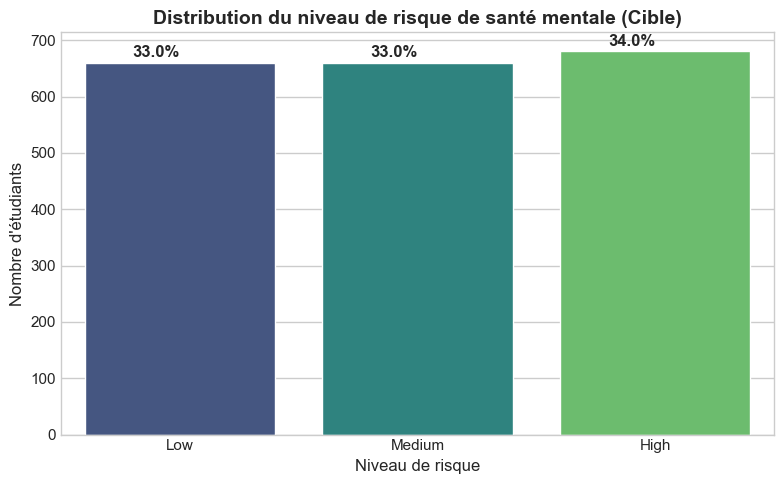

In [18]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Mental_Health_Risk', order=['Low', 'Medium', 'High'], palette='viridis')

plt.title("Distribution du niveau de risque de santé mentale (Cible)", fontsize=14, fontweight='bold')
plt.ylabel("Nombre d'étudiants")
plt.xlabel("Niveau de risque")

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_y() + p.get_height() + 5
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# - Distributions des Variables Numériques (Histogrammes)

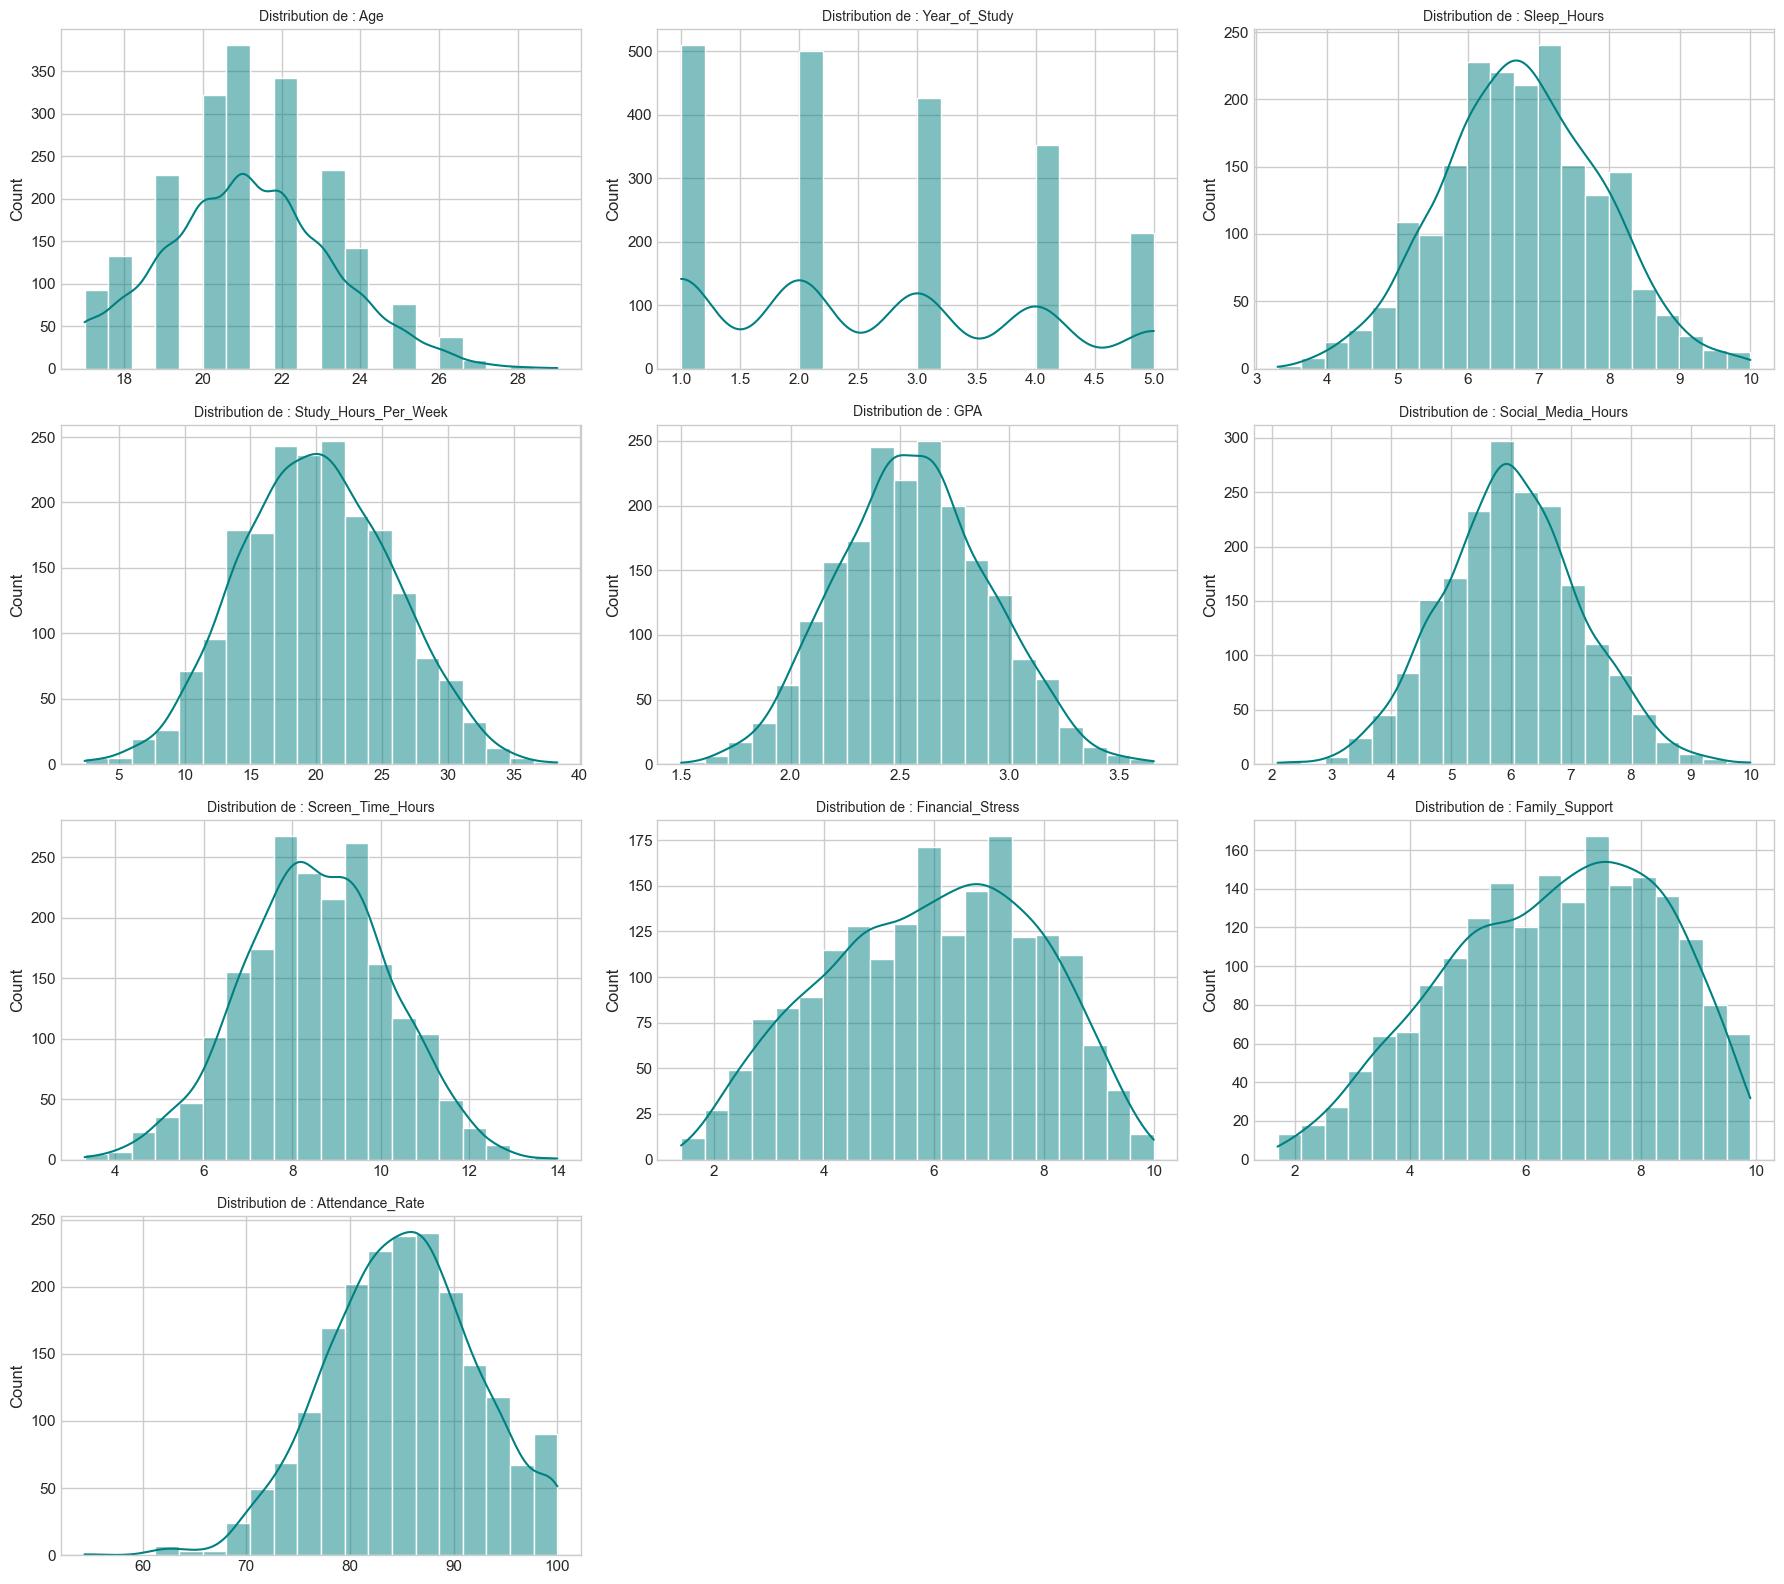

In [ ]:
import math

cols_num = df.select_dtypes(include=['float64', 'int64']).columns
n_cols = len(cols_num) 

n_cols_plot = 3
n_rows_plot = math.ceil(n_cols / n_cols_plot) 

fig, axes = plt.subplots(nrows=n_rows_plot, ncols=n_cols_plot, figsize=(18, 4 * n_rows_plot))
axes = axes.flatten()

for i, col in enumerate(cols_num):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal', bins=20)
    axes[i].set_title(f'Distribution de : {col}', fontsize=10)
    axes[i].set_xlabel('')

for j in range(n_cols, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# - Analyse des Variables Catégorielles (Countplots)

C:\Users\Youcode\AppData\Local\Temp\ipykernel_16860\2522987099.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Set2')
C:\Users\Youcode\AppData\Local\Temp\ipykernel_16860\2522987099.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Set2')
C:\Users\Youcode\AppData\Local\Temp\ipykernel_16860\2522987099.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Set2')
C:\Users\Youcode\AppData\Local\Temp\ipykernel_16860\2522987099.p

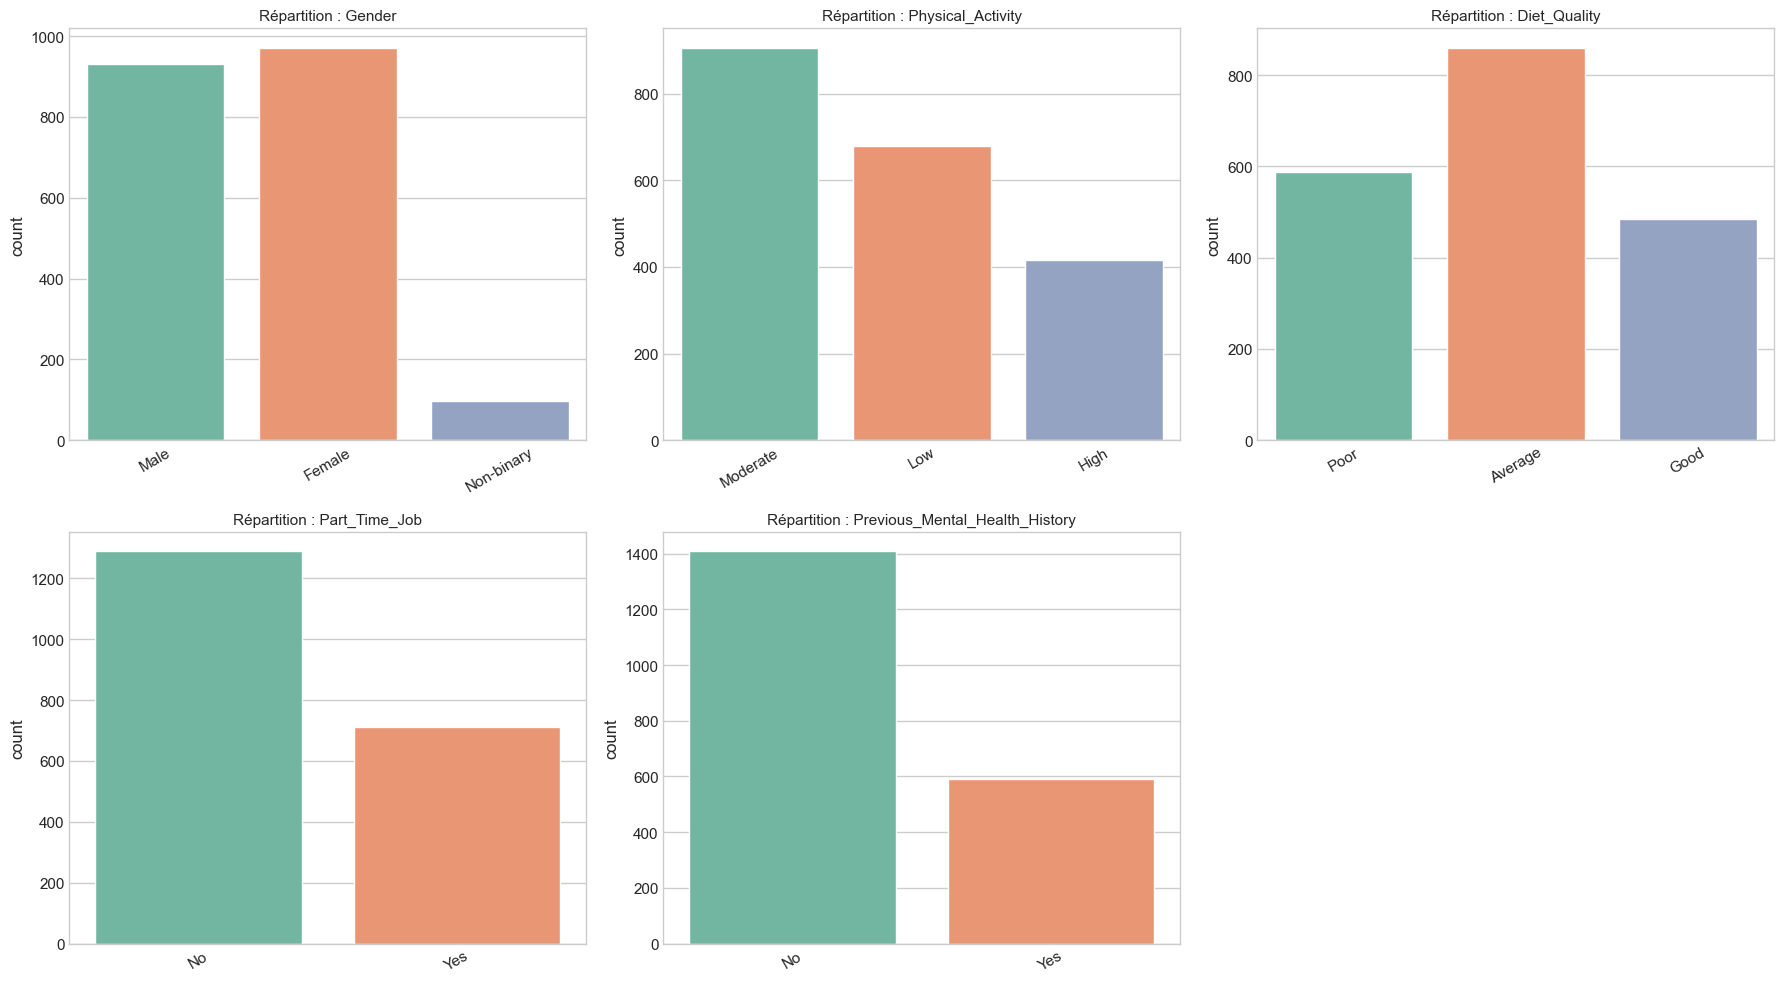

In [21]:
cols_cat = ['Gender', 'Physical_Activity', 'Diet_Quality', 'Part_Time_Job', 'Previous_Mental_Health_History']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cols_cat):
    sns.countplot(data=df, x=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Répartition : {col}', fontsize=11)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# - Analyse Bivariée - Numérique vs Cible (Boxplots)

C:\Users\Youcode\AppData\Local\Temp\ipykernel_16860\4215076631.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Mental_Health_Risk', y=col, ax=axes[i], order=['Low', 'Medium', 'High'], palette='coolwarm')
C:\Users\Youcode\AppData\Local\Temp\ipykernel_16860\4215076631.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Mental_Health_Risk', y=col, ax=axes[i], order=['Low', 'Medium', 'High'], palette='coolwarm')
C:\Users\Youcode\AppData\Local\Temp\ipykernel_16860\4215076631.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.

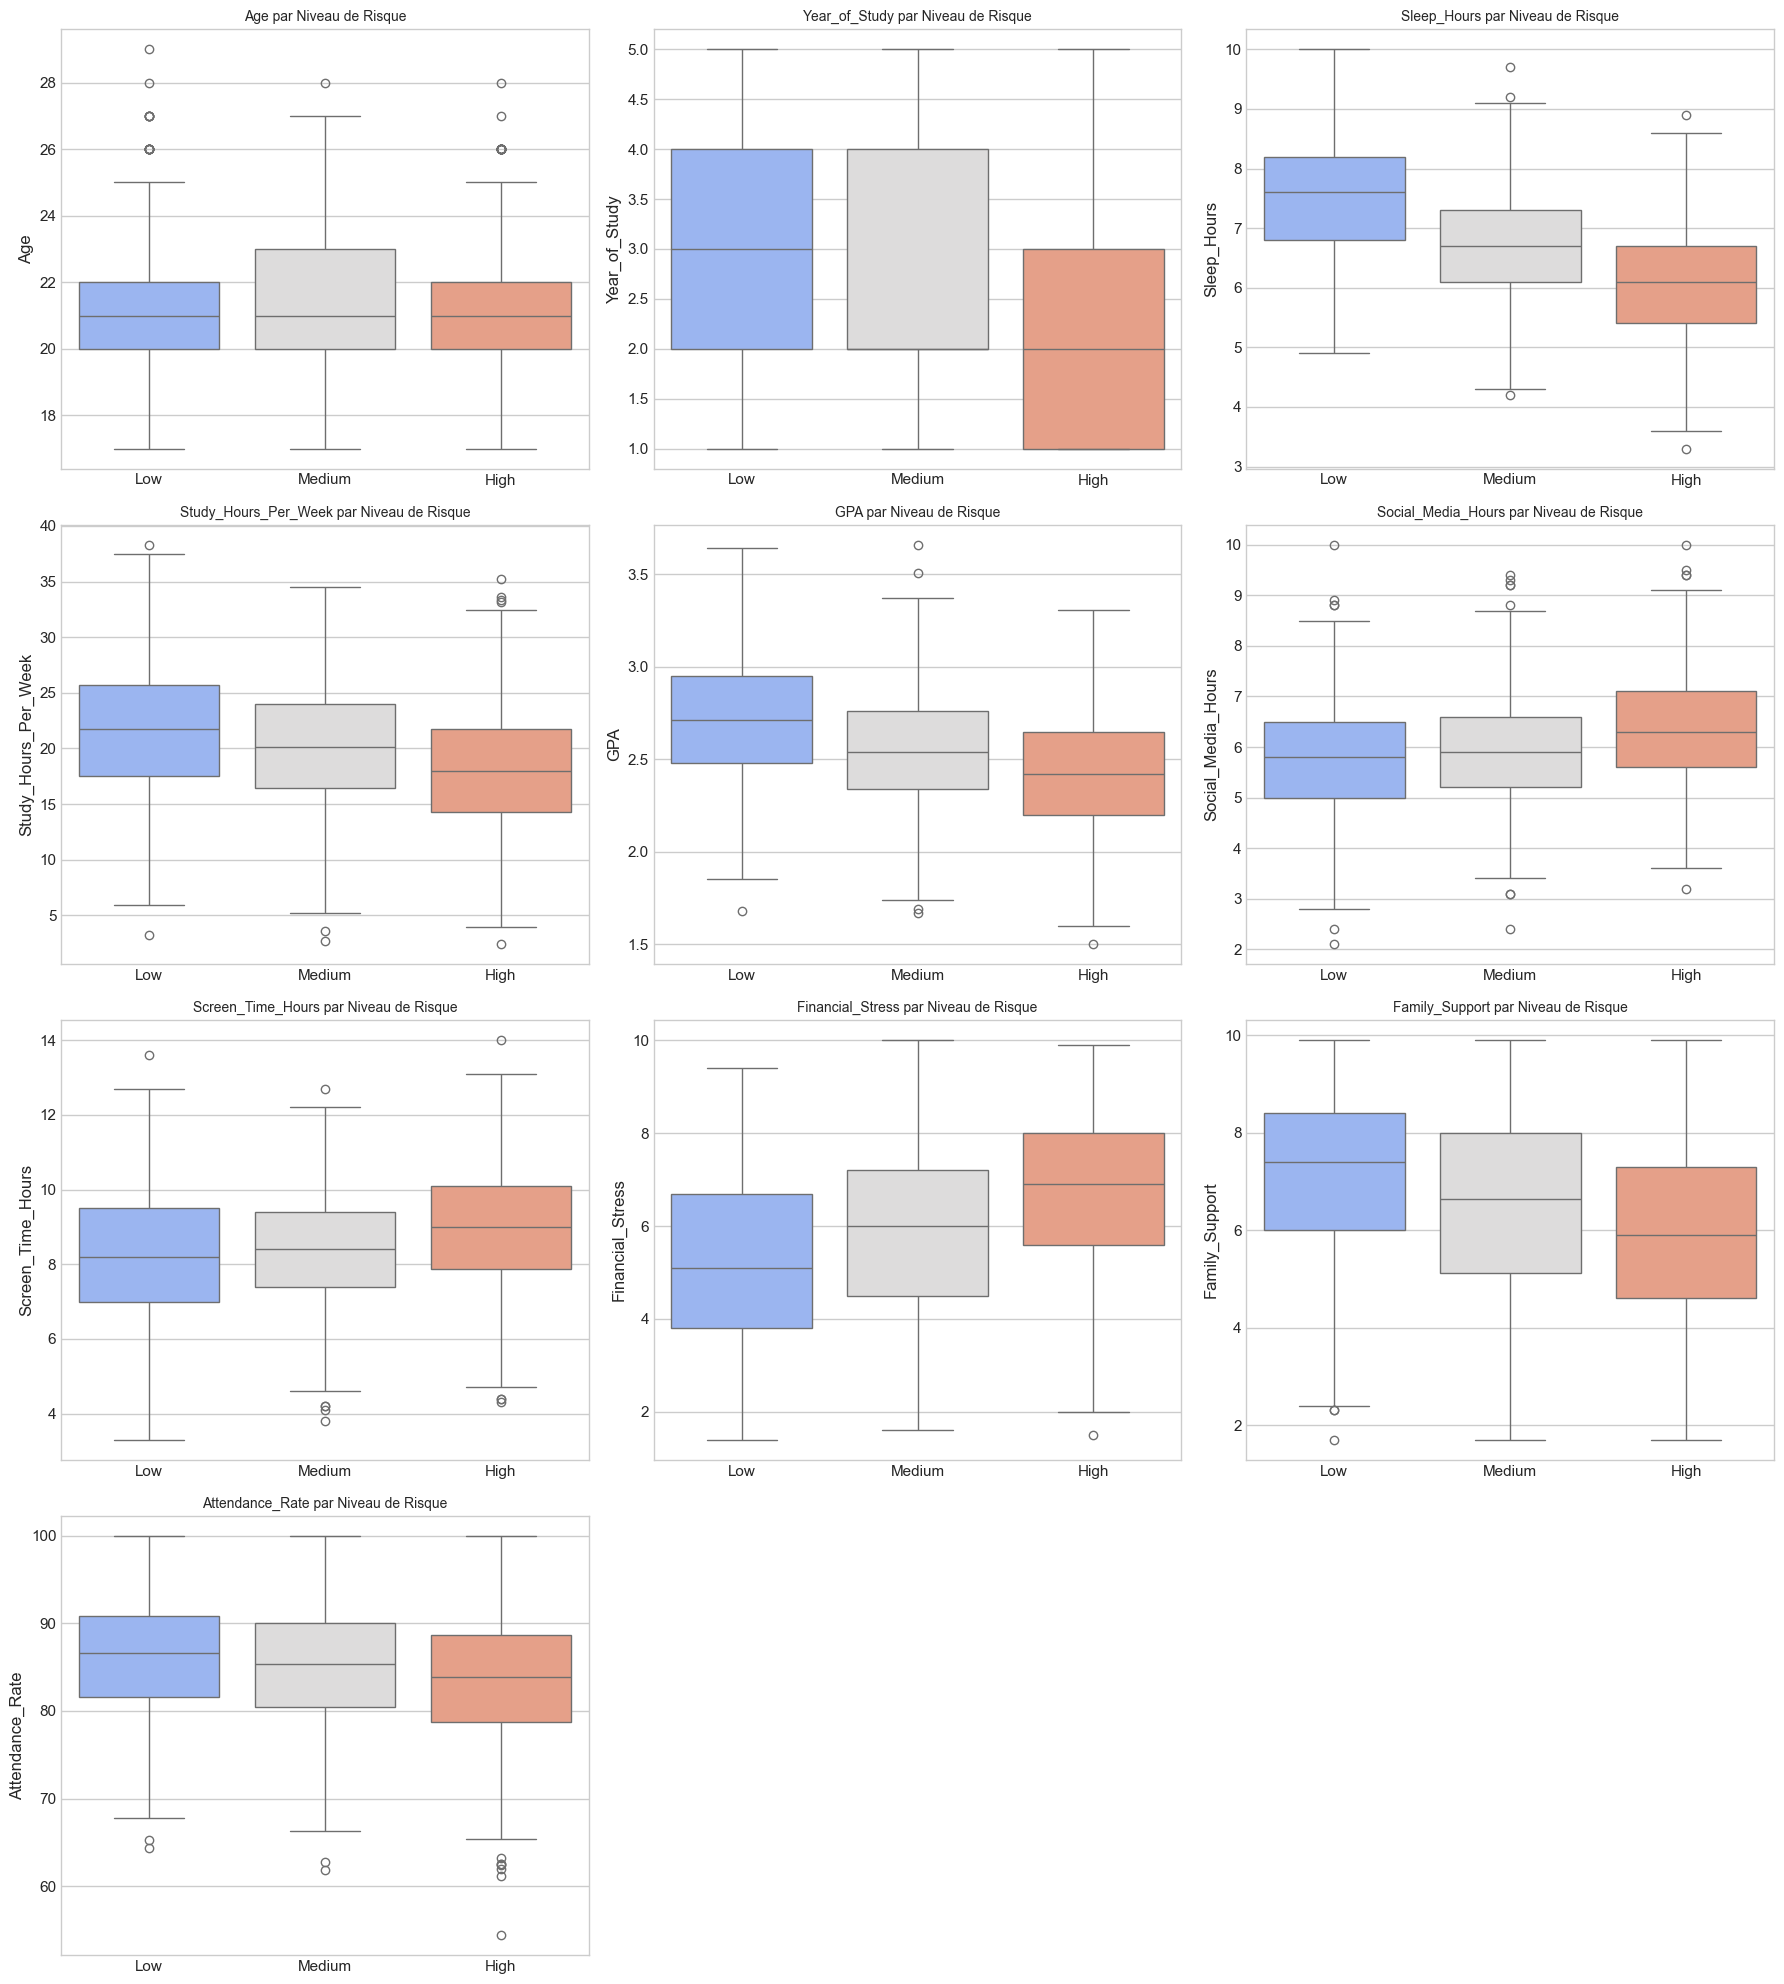

In [28]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(18, 20))
axes = axes.flatten()

for i, col in enumerate(cols_num):
    sns.boxplot(data=df, x='Mental_Health_Risk', y=col, ax=axes[i], order=['Low', 'Medium', 'High'], palette='coolwarm')
    axes[i].set_title(f'{col} par Niveau de Risque', fontsize=10)
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

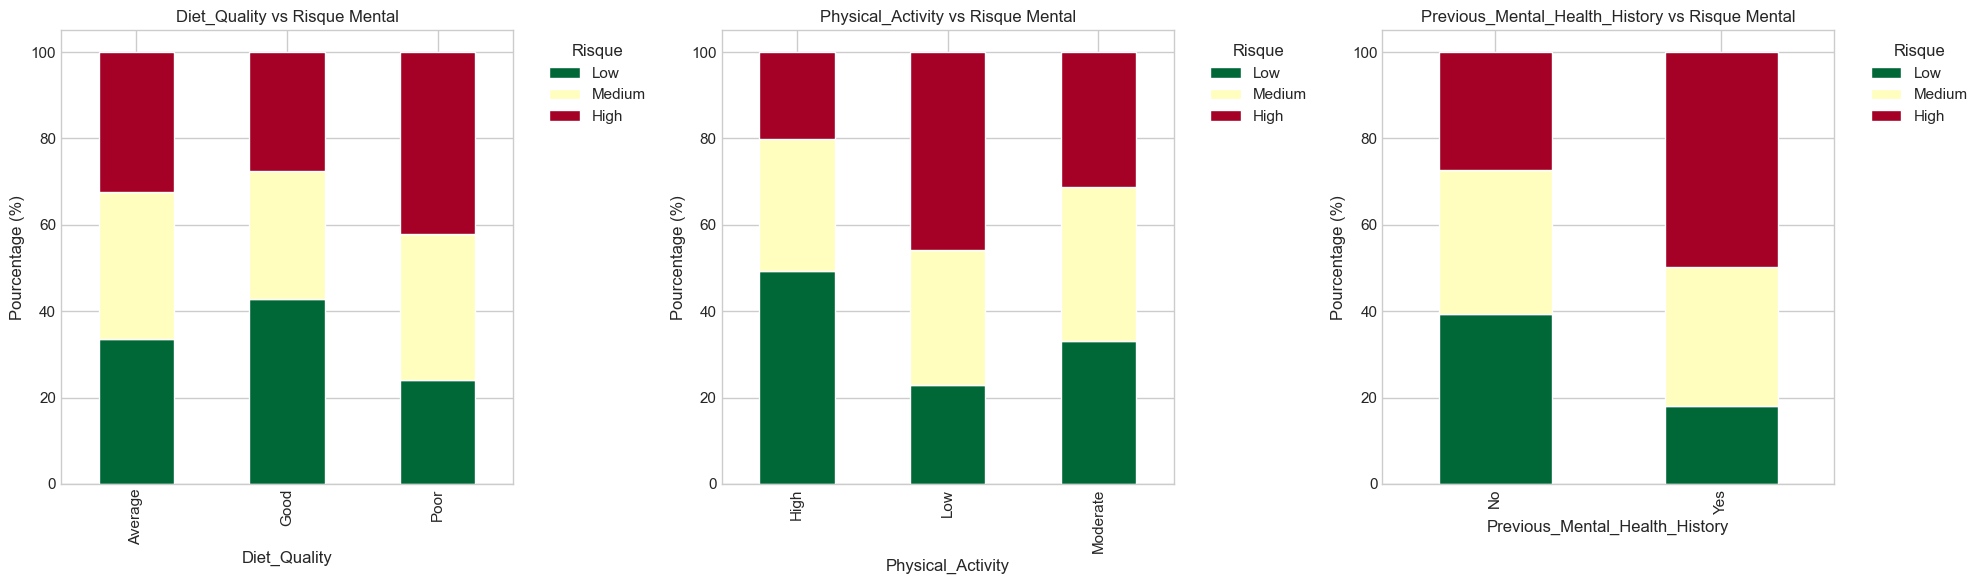

In [ ]:
cat_vars = ['Diet_Quality', 'Physical_Activity', 'Previous_Mental_Health_History']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(cat_vars):
    
    crosstab = pd.crosstab(df[col], df['Mental_Health_Risk'], normalize='index') * 100
    crosstab = crosstab[['Low', 'Medium', 'High']] 
    
    crosstab.plot(kind='bar', stacked=True, ax=axes[i], colormap='RdYlGn_r')
    axes[i].set_title(f'{col} vs Risque Mental')
    axes[i].set_ylabel('Pourcentage (%)')
    axes[i].legend(title='Risque', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# - Matrice de corrélation

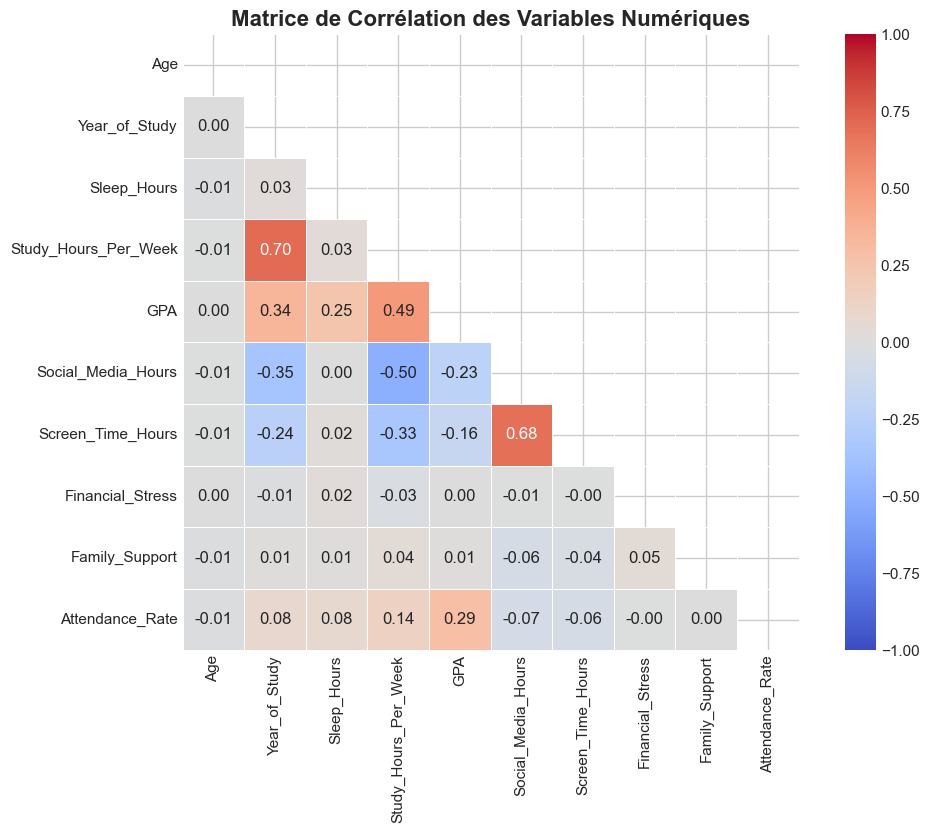

In [ ]:
plt.figure(figsize=(12, 8))
correlation_matrix = df[cols_num].corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
            vmin=-1, vmax=1, square=True, linewidths=.5)

plt.title("Matrice de Corrélation des Variables Numériques", fontsize=16, fontweight='bold')
plt.show()

# - Vérification de la cohérence (Age vs Year_of_Study)

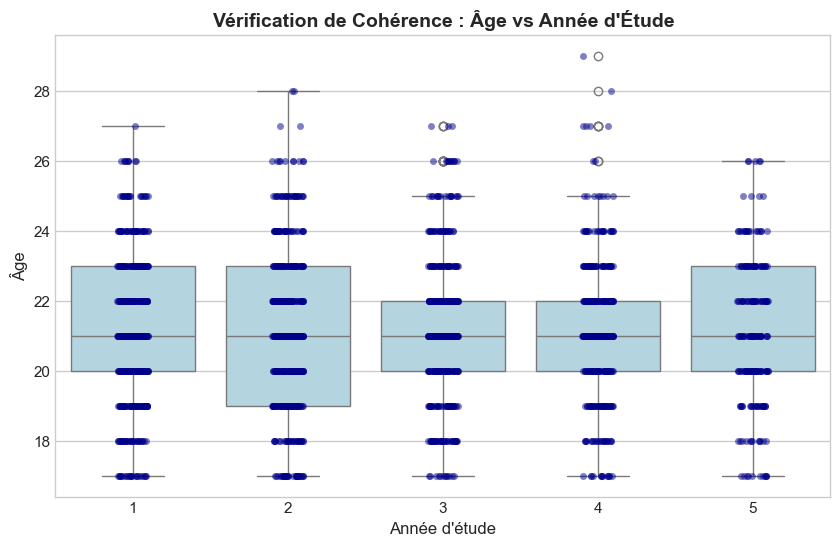

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='Year_of_Study', y='Age', color='lightblue')
sns.stripplot(data=df, x='Year_of_Study', y='Age', color='darkblue', alpha=0.5, jitter=True)

plt.title("Vérification de Cohérence : Âge vs Année d'Étude", fontsize=14, fontweight='bold')
plt.xlabel("Année d'étude")
plt.ylabel("Âge")
plt.show()

# - L'Effort vs La Performance (Study_Hours vs GPA)

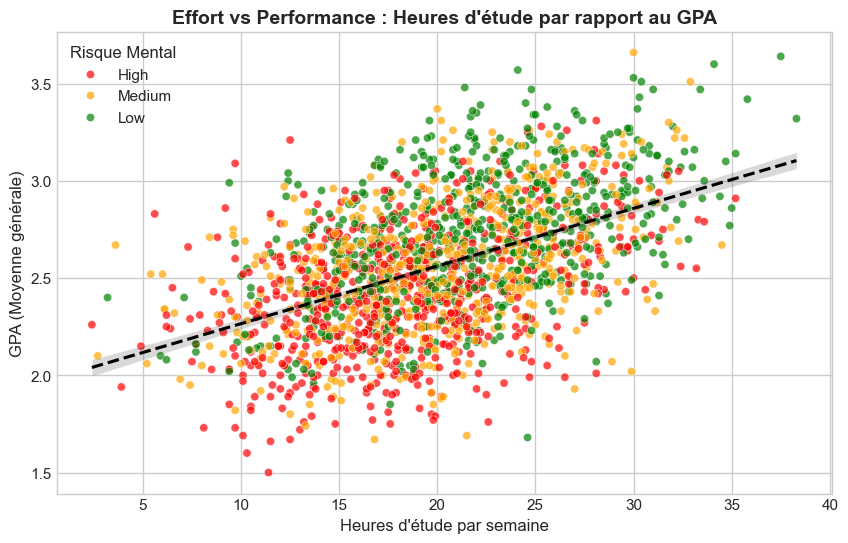

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Study_Hours_Per_Week', y='GPA', 
                hue='Mental_Health_Risk', palette={'Low': 'green', 'Medium': 'orange', 'High': 'red'},
                alpha=0.7)

sns.regplot(data=df, x='Study_Hours_Per_Week', y='GPA', scatter=False, color='black', line_kws={"linestyle":"--"})

plt.title("Effort vs Performance : Heures d'étude par rapport au GPA", fontsize=14, fontweight='bold')
plt.xlabel("Heures d'étude par semaine")
plt.ylabel("GPA (Moyenne générale)")
plt.legend(title='Risque Mental')
plt.show()

# - L'hygiène de vie (Screen Time, Sleep & Mental Health)

<Figure size 1000x600 with 0 Axes>

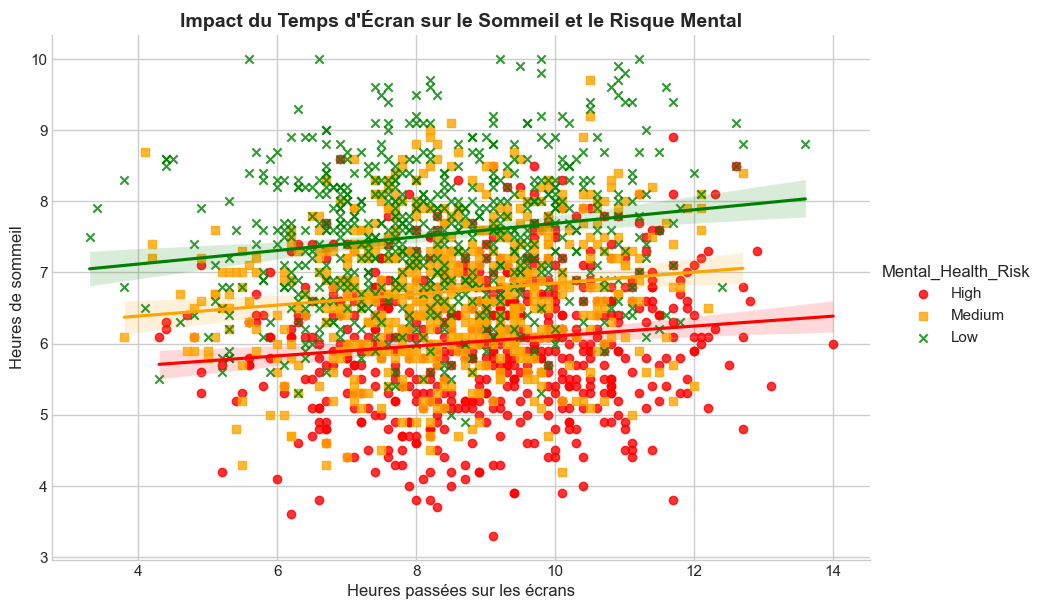

In [31]:
plt.figure(figsize=(10, 6))
sns.lmplot(data=df, x='Screen_Time_Hours', y='Sleep_Hours', 
           hue='Mental_Health_Risk', palette={'Low': 'green', 'Medium': 'orange', 'High': 'red'},
           height=6, aspect=1.5, markers=['o', 's', 'x'])

plt.title("Impact du Temps d'Écran sur le Sommeil et le Risque Mental", fontsize=14, fontweight='bold')
plt.xlabel("Heures passées sur les écrans")
plt.ylabel("Heures de sommeil")
plt.show()

# - Facteur socio-économique (Financial_Stress vs Part_Time_Job)

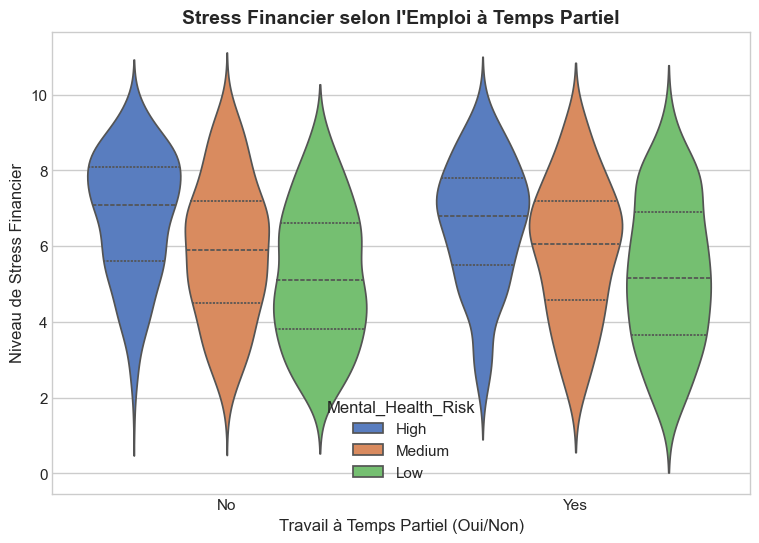

In [32]:
plt.figure(figsize=(9, 6))
sns.violinplot(data=df, x='Part_Time_Job', y='Financial_Stress', 
               hue='Mental_Health_Risk', split=False, 
               palette='muted', inner='quartile')

plt.title("Stress Financier selon l'Emploi à Temps Partiel", fontsize=14, fontweight='bold')
plt.xlabel("Travail à Temps Partiel (Oui/Non)")
plt.ylabel("Niveau de Stress Financier")
plt.show()